# Length of stay: k-nearest neighbors

Predicts the majority bin among the 5 nearest training animals, using Euclidean distance on the standardized and one-hot encoded features. It is sensitive to feature scaling and to the ~250 mostly one-hot dimensions.

**Task:** predict an animal's length-of-stay bin at intake: `<1 week`, `1-4 weeks`, `1-3 months`, `3+ months`. The bins are ordinal.
**Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal (see `eda/austindataprocessing.ipynb`).
**Metrics:** accuracy, macro-F1, per-class precision/recall, and quadratic weighted kappa (QWK; rewards predictions that land close to the true bin).
**This notebook uses default hyperparameters** (no tuning). The only exceptions are settings that don't change the model itself: `random_state=utils.SEED`, `n_jobs=-1`, and an iteration cap where the default fails to converge. Tuning comes later.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()   # test is held out; models are compared on val
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
train["los_bin"].value_counts(normalize=True).reindex(utils.LOS_BIN_LABELS).round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
train 126,758  val 10,544  (test 21,835 untouched)


los_bin
<1 week       0.559
1-4 weeks     0.262
1-3 months    0.139
3+ months     0.040
Name: proportion, dtype: float64

In [2]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_jobs=-1)
model

,n_neighbors,5
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,-1


== k-nearest neighbors ==  macro-F1 0.331  accuracy 0.435
              precision    recall  f1-score   support

     <1 week       0.53      0.58      0.55      4554
   1-4 weeks       0.37      0.38      0.37      3420
  1-3 months       0.33      0.31      0.32      2017
   3+ months       0.15      0.05      0.08       553

    accuracy                           0.44     10544
   macro avg       0.35      0.33      0.33     10544
weighted avg       0.42      0.44      0.43     10544

quadratic weighted kappa: 0.207


train accuracy 0.707  |  fit 0.5s  predict 3.2s


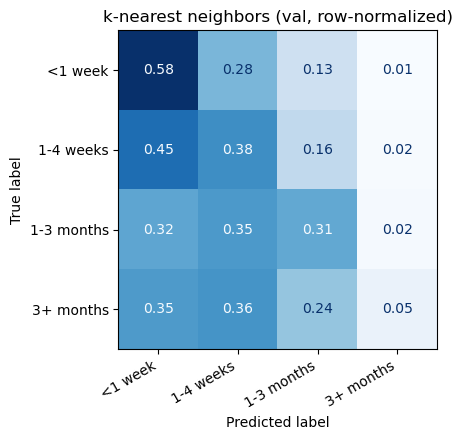

In [3]:
pipe, metrics = utils.evaluate_classifier(model, train, val, name="k-nearest neighbors",
                                           results_dir=RESULTS_DIR)

## Hyperparameter tuning (light–medium)

**Randomized search with a time-ordered inner split** (`utils.tune_classifier`):
- Training years are split again, by time and grouped by animal: candidates are fit on intakes before 2021 and scored on 2021 intakes.
- Candidates are ranked by **macro-F1**, so all four bins count equally, not just the dominant `<1 week`.
- The best setting is then refit on the full training set (< 2022) and scored on the **same 2022 val set** as the untuned model.
- Neither val nor test is seen during the search, so the comparison below is fair.

Searched: number of neighbors and distance weighting (a full 10-point grid). More neighbors smooths predictions and reduces overfitting.

In [4]:


base = utils.with_params(model, {})  # unfitted copy of the untuned model
space = {
    'n_neighbors': [5, 15, 25, 50, 100],
    'weights': ['uniform', 'distance'],
}

best, search_results, tune_info = utils.tune_classifier(
    base, space, train, name="k-nearest neighbors (tuned)", n_iter=10, results_dir=RESULTS_DIR)
search_results.head(10)

time_group_split: dropped 592 rows (0.5%) belonging to animals first seen in an earlier split


k-nearest neighbors (tuned): 10 candidates in 0.5 min | sub-train 115,479, inner-val 10,687 | best inner-val f1_macro 0.320
best params: {'weights': 'uniform', 'n_neighbors': 15}


,weights,n_neighbors,inner_val_f1_macro,mean_fit_time
0,uniform,15,0.319874,0.634506
1,uniform,5,0.318849,0.589503
2,distance,15,0.317302,0.531285
3,distance,5,0.316655,0.629051
4,uniform,25,0.314345,0.557715
5,distance,25,0.312523,0.592091
6,uniform,50,0.301134,0.571458
7,distance,50,0.299663,0.608252
8,uniform,100,0.285119,0.624393
9,distance,100,0.284740,0.555922


== k-nearest neighbors (tuned) ==  macro-F1 0.322  accuracy 0.462
              precision    recall  f1-score   support

     <1 week       0.52      0.69      0.59      4554
   1-4 weeks       0.39      0.35      0.36      3420
  1-3 months       0.39      0.27      0.32      2017
   3+ months       0.15      0.01      0.01       553

    accuracy                           0.46     10544
   macro avg       0.36      0.33      0.32     10544
weighted avg       0.43      0.46      0.44     10544

quadratic weighted kappa: 0.206


train accuracy 0.643  |  fit 0.5s  predict 3.3s


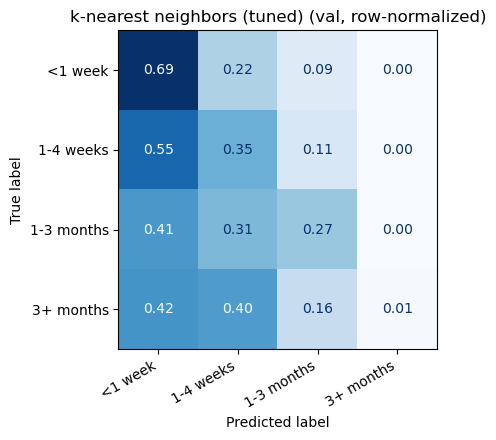

In [5]:
tuned = utils.with_params(base, best)
pipe_tuned, metrics_tuned = utils.evaluate_classifier(
    tuned, train, val, name="k-nearest neighbors (tuned)", results_dir=RESULTS_DIR, extra=tune_info)

### Untuned vs. tuned (val 2022)

In [6]:
pd.DataFrame([metrics, metrics_tuned]).set_index("model")[
    ["accuracy", "macro_f1", "qwk", "train_accuracy"]
    + [f"recall_{c}" for c in utils.LOS_BIN_LABELS]].round(3)

,accuracy,macro_f1,qwk,train_accuracy,recall_<1 week,recall_1-4 weeks,recall_1-3 months,recall_3+ months
model,,,,,,,,
k-nearest neighbors,0.435,0.331,0.207,0.707,0.581,0.375,0.312,0.051
k-nearest neighbors (tuned),0.462,0.322,0.206,0.643,0.690,0.345,0.269,0.007
